# Euler System of Gas Dynamics

In [1]:
import math, numpy
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import pyplot
from ufl import *
from dune.grid import structuredGrid, reader
from dune.fem.space import dgonb, finiteVolume
from dune.fem.function import gridFunction
from dune.femdg import femDGOperator
from dune.femdg.rk import femdgStepper
from dune.fem.utility import lineSample

# use a dg space if order>0 else a finite volume space
def getSpace( gv, order ):
    return finiteVolume( gridView, dimRange=4 ) if order==0 else\
           dgonb( gridView, dimRange=4, order=order )

Basic model for hyperbolic conservation law

In [2]:
class Model:
    gamma = 1.4
    # helper function
    def toPrim(U):
        v = as_vector( [U[i]/U[0] for i in range(1,3)] )
        kin = dot(v,v) * U[0] / 2
        pressure = (Model.gamma-1)*(U[3]-kin)
        return U[0], v, pressure

    # interface methods for model
    def F_c(t,x,U):
        rho, v, p = Model.toPrim(U)
        return as_matrix( [
                  [rho*v[0], rho*v[1]],
                  [rho*v[0]*v[0] + p, rho*v[0]*v[1]],
                  [rho*v[0]*v[1], rho*v[1]*v[1] + p],
                  [(U[3]+p)*v[0], (U[3]+p)*v[1]] ] )

    # simple 'outflow' boundary conditions on all boundaries
    boundary = {range(1,5): lambda t,x,U: U}

    # interface method needed for LLF and time step control
    def maxLambda(t,x,U,n):
        rho, v, p = Model.toPrim(U)
        return abs(dot(v,n)) + sqrt(Model.gamma*p/rho)

Add methods for limiting

In [3]:
def velocity(t,x,U):
    _, v ,_ = Model.toPrim(U)
    return v
def physical(t,x,U):
    rho, _, p = Model.toPrim(U)
    return conditional( rho>1e-8, conditional( p>1e-8 , 1, 0 ), 0 )
def jump(t,x,U,V):
    _,_, pL = Model.toPrim(U)
    _,_, pR = Model.toPrim(V)
    return (pL - pR)/(0.5*(pL + pR))
Model.velocity = velocity
Model.physical = physical
Model.jump     = jump

Method to evolve the solution in time

In [4]:
def evolve(space, u_h, limiter="MinMod"):
    lu_h = u_h.localFunction()
    @gridFunction(space.grid,name="rho",order=space.order)
    def rho(e,x):
        lu_h.bind(e)
        return lu_h(x)[0]
    operator = femDGOperator(Model, space, limiter=limiter) # note: that u_h.space fails since not ufl_space
    stepper  = femdgStepper(order=space.order+1 if space.order>0 else 2, operator=operator)
    rho.plot()
    operator.applyLimiter(u_h)
    rho.plot()
    t = 0
    saveStep = 0.01
    c = 0
    # fig = pyplot.figure(figsize=(30,10))
    # rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
    while t < 0.3:
        operator.setTime(t)
        t += stepper(u_h)
        if t > saveStep:
            print(t)
            saveStep += 0.1
            c += 1
            # rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
            # rho.plot()
    # return lineSample(u_h,[0,0],[1,1],200)
    res = numpy.zeros((2,space.grid.size(0)))
    for i,e in enumerate(space.grid.elements):
        x = e.geometry.center
        res[0][i] = x.two_norm
        res[1][i] = rho(e,e.geometry.toLocal(x))
    # pyplot.show()
    return res

A radial Rieman problem

Triangle grid with minmod limiter


femDGOperator: Limiter = MinMod


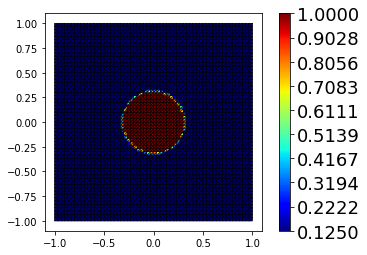

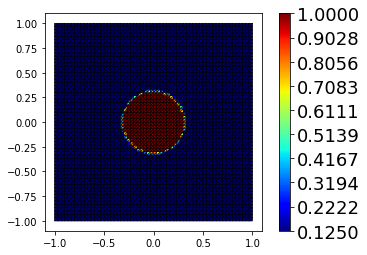

0.010840262969637098


0.11079746918309913


0.21038445745362766


Triangle grid without limiter


femDGOperator: Limiter = unlimited


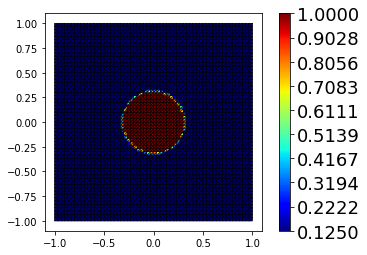

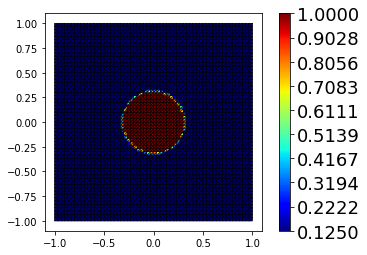

0.010585465679073815


8.089619106880421e+307
*************************************
Dual grid with minmod limiter


femDGOperator: Limiter = MinMod


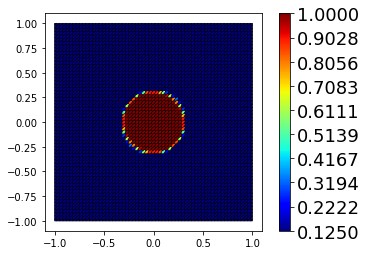

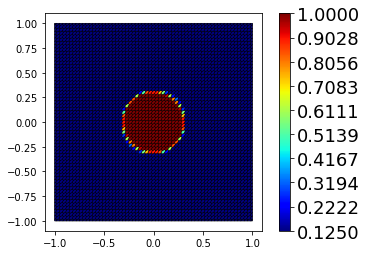

0.011023963796102019


0.11023963796102007


0.21103016409680916


Dual grid without limiter


femDGOperator: Limiter = unlimited


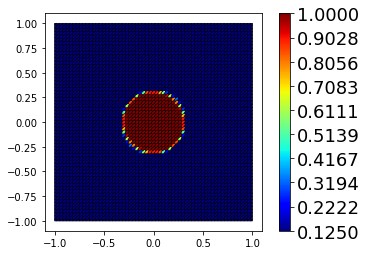

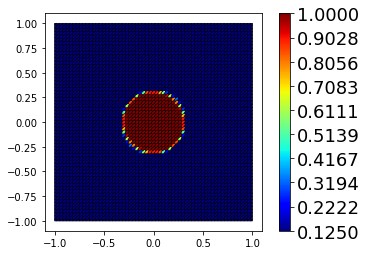

0.010049552090864673


8.089619106880421e+307


In [5]:
x = SpatialCoordinate(triangle)
initial = conditional(dot(x,x)<0.1,as_vector([1,0,0,2.5]),
                                   as_vector([0.125,0,0,0.25]))

domain = (reader.dgf, "triangle.dgf")

res = []

from dune.alugrid import aluSimplexGrid as simplexGrid
try:
    from dune.polygongrid import polygonGrid
    gridView = polygonGrid( domain, dualGrid=False )
    # gridView.plot()
except ImportError:
    print("dune.polygongrid module not found using a simplex grid instead - ignored")
    gridView = simplexGrid( domain, dimgrid=2 )

# fix the order to use
order = 1

print("Triangle grid with minmod limiter", flush=True)
space = getSpace( gridView, order )
u_h   = space.interpolate( initial, name="solution")
res  += [evolve(space,u_h)]

print("Triangle grid without limiter", flush=True)
u_h   = space.interpolate( initial, name="solution")
res  += [evolve(space,u_h,limiter=None)]

print("*************************************")

try:
    from dune.polygongrid import polygonGrid
    gridView = polygonGrid( domain, dualGrid=True )
    # gridView.plot()
except ImportError:
    print("dune.polygongrid module not found using a simplex grid instead - ignored")
    gridView = simplexGrid( domain, dimgrid=2 )
space = getSpace( gridView, order )

print("Dual grid with minmod limiter", flush=True)
u_h   = space.interpolate( initial, name="solution")
res  += [evolve(space,u_h)]

print("Dual grid without limiter", flush=True)
u_h   = space.interpolate( initial, name="solution")
res  += [evolve(space,u_h,limiter=None)]

Solutions along the diagonal

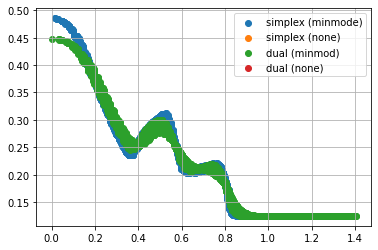

In [6]:
color = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
fig, ax = pyplot.subplots()
ax.scatter(res[0][0],res[0][1], color=color[0], label='simplex (minmode)')
ax.scatter(res[1][0],res[1][1], color=color[1], label='simplex (none)')
ax.scatter(res[2][0],res[2][1], color=color[2], label='dual (minmod)')
ax.scatter(res[3][0],res[3][1], color=color[3], label='dual (none)')
ax.legend()
ax.grid(True)
pyplot.show()